# Language effect per vote

**Goal:** For each of the 136 votes, estimate how much language region shifts yes_pct once demographics are held constant, then summarise the size of that gap across votes.

**Model (per vote):** yes_pct ~ language + urban_rural + share_65plus + log(avg_income), weighted by valid_votes. German is the reference group, so each language coefficient is the gap in percentage points compared with German-speaking municipalities with the same demographics.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

df = pd.read_parquet("../data/processed/votes_demographics.parquet")
df["log_income"] = np.log(df["avg_income"])

model_df = df.dropna(subset=["avg_income"])
dropped = df.loc[df["avg_income"].isna(), "bfs_nr"].nunique()
print(f"{model_df['bfs_nr'].nunique()} municipalities in the regressions, {dropped} dropped for missing income")

2086 municipalities in the regressions, 19 dropped for missing income


## One regression per vote

In [2]:
formula = "yes_pct ~ C(language, Treatment('de')) + urban_rural + share_65plus + log_income"

rows = []
for vote_id, vote in model_df.groupby("vote_id"):
    fit = smf.wls(formula, data=vote, weights=vote["valid_votes"]).fit()
    rows.append({
        "vote_id": vote_id,
        "date": vote["date"].iloc[0],
        "title_en": vote["title_en"].iloc[0],
        "fr": fit.params["C(language, Treatment('de'))[T.fr]"],
        "it": fit.params["C(language, Treatment('de'))[T.it]"],
        "rm": fit.params["C(language, Treatment('de'))[T.rm]"],
        "r2": fit.rsquared,
    })

results = pd.DataFrame(rows)
print(len(results), "votes")
results.head(10).round({"fr": 1, "it": 1, "rm": 1, "r2": 2})

136 votes


,vote_id,date,title_en,fr,it,rm,r2
0,5480,2010-03-07,Constitutional article on research on humans,9.7,4.3,-4.0,0.58
1,5490,2010-03-07,Popular initiative ‘Against animal cruelty and...,-8.5,6.8,2.9,0.44
2,5500,2010-03-07,"Federal law on occupational old-age, survivors...",-8.6,-6.5,12.7,0.50
3,5510,2010-09-26,Federal law on compulsory unemployment insuran...,-16.8,-13.5,10.4,0.66
4,5521,2010-11-28,Popular initiative ‘For the expulsion of crimi...,-11.3,6.5,-14.0,0.39
5,5522,2010-11-28,Federal decree on the expulsion and extraditio...,-0.5,-1.8,5.7,0.26
6,5523,2010-11-28,Expulsion Initiative and Counter-proposal: dec...,-11.1,5.7,-13.3,0.40
7,5530,2010-11-28,Popular initiative ‘For fair taxes. Stop the a...,6.2,-2.3,-3.1,0.30
8,5540,2011-02-13,Popular initiative ‘For protection against arm...,10.1,-4.6,1.4,0.51
9,5550,2012-03-11,Popular initiative 'Put an end to the unrestri...,-3.1,-5.5,-13.1,0.16


## Size of the language gap

In [3]:
summary = pd.DataFrame({
    "avg_abs_coef": results[["fr", "it", "rm"]].abs().mean(),
    "median_abs_coef": results[["fr", "it", "rm"]].abs().median(),
    "votes_above_de": (results[["fr", "it", "rm"]] > 0).sum(),
    "votes_below_de": (results[["fr", "it", "rm"]] < 0).sum(),
})
summary.round(1)

,avg_abs_coef,median_abs_coef,votes_above_de,votes_below_de
fr,9.3,7.9,82,54
it,7.0,5.5,96,40
rm,5.9,5.3,86,50


**Finding:** 

## French coefficient per vote

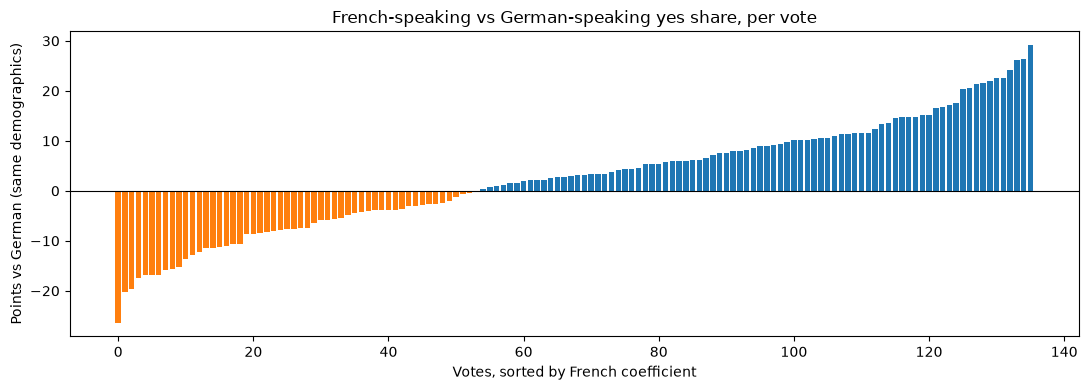

In [4]:
fr_sorted = results.sort_values("fr").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(fr_sorted.index, fr_sorted["fr"], color=np.where(fr_sorted["fr"] > 0, "tab:blue", "tab:orange"))
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Votes, sorted by French coefficient")
ax.set_ylabel("Points vs German (same demographics)")
ax.set_title("French-speaking vs German-speaking yes share, per vote")
plt.tight_layout()
plt.show()

In [5]:
cols = ["date", "title_en", "fr", "it", "rm", "r2"]
print("Largest French-German gaps:")
display(results.reindex(results["fr"].abs().sort_values(ascending=False).index)[cols].head(10).round({"fr": 1, "it": 1, "rm": 1, "r2": 2}))

Largest French-German gaps:


,date,title_en,fr,it,rm,r2
76,2018-09-23,Federal Popular Initiative ‘For food sovereign...,29.1,12.5,0.7,0.81
132,2025-09-28,Federal decree on cantonal property taxes on s...,-26.4,-3.8,0.3,0.63
75,2018-09-23,"Federal Popular Initiative ‘For healthy, envir...",26.3,10.5,1.1,0.69
13,2012-03-11,Federa law on fixed booked prices,26.1,8.8,9.5,0.82
110,2022-05-15,Transplantation Act,24.2,12.6,9.5,0.79
119,2024-03-03,Initiative for a 13th OASI pension payment,22.6,15.9,-4.5,0.72
121,2024-06-09,Popular initiative ‘Keep health insurance prem...,22.5,15.6,-6.1,0.71
40,2014-09-28,Popular initiative 'For a system of public hea...,22.0,11.1,-6.2,0.64
88,2020-09-27,Amendment of the Loss of Earnings Compensation...,21.6,13.1,6.6,0.62
21,2013-03-03,Federal resolution on family policy,21.4,18.4,10.2,0.65


**Finding:** 